# Restart-safe version — model checkpoints and analysis

**First run:** Run the notebook top-to-bottom once to train and save all four models. Approve Google Drive access in the persistent-storage setup cell.

**After a runtime reset:** Run the dependency-installation cell, then the Google Drive setup cell, then run the **QUICK RESTORE** cell (just after the Transformer save cell). The QUICK RESTORE cell recreates all four models, reloads the saved weights, rebuilds test predictions and analysis variables, and does **not** train the models.

**Important:** The checkpoint files must already exist in `MyDrive/news_project_results`. Training cells intentionally retrain if you execute them. Some cells that create files (CSV/plots/ZIPs) should be run after QUICK RESTORE and may depend on the corresponding input files being present.

In [ ]:
!pip install -q datasets scikit-learn

In [ ]:
# Persistent storage for model checkpoints, metrics, histories and plots.
# Run this cell after the package-installation cell in each new Colab runtime.
from google.colab import drive
drive.mount("/content/drive")

import os
import shutil

RESULTS_DIR = "/content/drive/MyDrive/news_project_results"
LOCAL_RESULTS_DIR = "/content/news_project_results"
os.makedirs(RESULTS_DIR, exist_ok=True)

# Migrate existing outputs from this runtime if they exist.
if os.path.isdir(LOCAL_RESULTS_DIR):
    for filename in os.listdir(LOCAL_RESULTS_DIR):
        src = os.path.join(LOCAL_RESULTS_DIR, filename)
        dst = os.path.join(RESULTS_DIR, filename)
        if os.path.isfile(src) and not os.path.exists(dst):
            shutil.copy2(src, dst)

print("Persistent results directory:", RESULTS_DIR)


Mounted at /content/drive
Persistent results directory: /content/drive/MyDrive/news_project_results


In [ ]:
from datasets import load_dataset

# Download the AG News dataset
dataset = load_dataset("fancyzhx/ag_news")

print(dataset)
print("\nTraining example:")
print(dataset["train"][0])

README.md:   0%|          | 0.00/8.07k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 18.6MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 1.23MB            

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/120000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/7600 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 120000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 7600
    })
})

Training example:
{'text': "Wall St. Bears Claw Back Into the Black (Reuters) Reuters - Short-sellers, Wall Street's dwindling\\band of ultra-cynics, are seeing green again.", 'label': 2}


In [ ]:
import pandas as pd

train_df = pd.DataFrame(dataset["train"])
test_df = pd.DataFrame(dataset["test"])

print("Training shape:", train_df.shape)
print("Testing shape:", test_df.shape)

print("\nFirst five training examples:")
display(train_df.head())

print("\nClass distribution:")
print(train_df["label"].value_counts().sort_index())

Training shape: (120000, 2)
Testing shape: (7600, 2)

First five training examples:


,text,label
0,Wall St. Bears Claw Back Into the Black (Reute...,2
1,Carlyle Looks Toward Commercial Aerospace (Reu...,2
2,Oil and Economy Cloud Stocks' Outlook (Reuters...,2
3,Iraq Halts Oil Exports from Main Southern Pipe...,2
4,"Oil prices soar to all-time record, posing new...",2



Class distribution:
label
0    30000
1    30000
2    30000
3    30000
Name: count, dtype: int64


count    120000.000000
mean         37.847450
std          10.085245
min           8.000000
25%          32.000000
50%          37.000000
75%          43.000000
max         177.000000
Name: text_length, dtype: float64


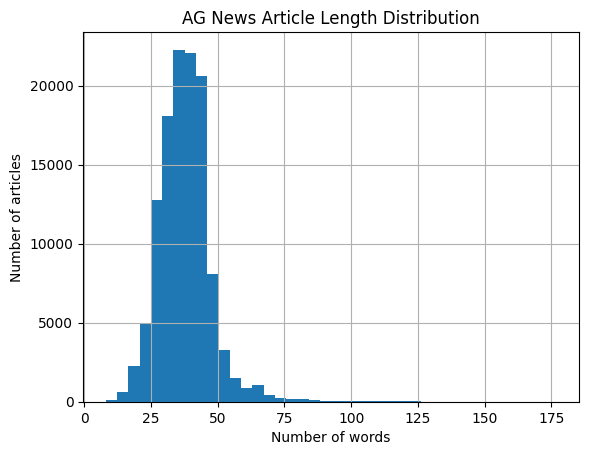

In [ ]:
import matplotlib.pyplot as plt

train_df["text_length"] = train_df["text"].str.split().str.len()

print(train_df["text_length"].describe())

train_df["text_length"].hist(bins=40)
plt.xlabel("Number of words")
plt.ylabel("Number of articles")
plt.title("AG News Article Length Distribution")
plt.show()

#Text Preprocessing

In [ ]:
from sklearn.model_selection import train_test_split

SEED = 42

train_data = dataset["train"]

# Use 10% of the original training set for validation
split = train_data.train_test_split(
    test_size=0.1,
    seed=SEED,
    stratify_by_column="label"
)

train_data = split["train"]
val_data = split["test"]
test_data = dataset["test"]

print("Training samples:", len(train_data))
print("Validation samples:", len(val_data))
print("Testing samples:", len(test_data))

Training samples: 108000
Validation samples: 12000
Testing samples: 7600


In [ ]:
import re
from collections import Counter

PAD_TOKEN = "<PAD>"
UNK_TOKEN = "<UNK>"

def tokenize(text):
    return re.findall(r"[A-Za-z]+(?:'[A-Za-z]+)?|[0-9]+|[^\w\s]", text.lower())

# Build vocabulary using training articles only
word_counts = Counter()

for item in train_data:
    word_counts.update(tokenize(item["text"]))

MAX_VOCAB_SIZE = 30000

vocab = {
    PAD_TOKEN: 0,
    UNK_TOKEN: 1
}

for word, _ in word_counts.most_common(MAX_VOCAB_SIZE - 2):
    vocab[word] = len(vocab)

print("Vocabulary size:", len(vocab))
print("Sample vocabulary entries:", list(vocab.items())[:20])

Vocabulary size: 30000
Sample vocabulary entries: [('<PAD>', 0), ('<UNK>', 1), ('.', 2), ('the', 3), (',', 4), ('-', 5), ('to', 6), ('a', 7), ('of', 8), ('in', 9), (';', 10), ('and', 11), ('on', 12), ('for', 13), ('#', 14), ('39', 15), ('(', 16), (')', 17), ('s', 18), ('that', 19)]


In [ ]:
import torch
from torch.utils.data import Dataset, DataLoader

PAD_IDX = vocab[PAD_TOKEN]
UNK_IDX = vocab[UNK_TOKEN]
MAX_LEN = 100

def encode_text(text):
    tokens = tokenize(text)[:MAX_LEN]
    token_ids = [vocab.get(token, UNK_IDX) for token in tokens]

    # Pad shorter articles
    token_ids += [PAD_IDX] * (MAX_LEN - len(token_ids))

    return token_ids

class NewsDataset(Dataset):
    def __init__(self, hf_dataset):
        self.texts = hf_dataset["text"]
        self.labels = hf_dataset["label"]

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, index):
        input_ids = encode_text(self.texts[index])
        label = self.labels[index]

        return (
            torch.tensor(input_ids, dtype=torch.long),
            torch.tensor(label, dtype=torch.long)
        )

train_dataset = NewsDataset(train_data)
val_dataset = NewsDataset(val_data)
test_dataset = NewsDataset(test_data)

BATCH_SIZE = 128

train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE, shuffle=True
)
val_loader = DataLoader(
    val_dataset, batch_size=BATCH_SIZE, shuffle=False
)
test_loader = DataLoader(
    test_dataset, batch_size=BATCH_SIZE, shuffle=False
)

x_batch, y_batch = next(iter(train_loader))

print("Input batch shape:", x_batch.shape)
print("Label batch shape:", y_batch.shape)
print("First 10 token IDs:", x_batch[0][:10].tolist())
print("First label:", y_batch[0].item())

Input batch shape: torch.Size([128, 100])
Label batch shape: torch.Size([128])
First 10 token IDs: [43, 7412, 57, 5, 60, 9, 67, 198, 7089, 12380]
First label: 1


In [ ]:
import torch.nn as nn

class MLPClassifier(nn.Module):
    def __init__(
        self,
        vocab_size,
        embedding_dim=128,
        hidden_dim=128,
        num_classes=4,
        dropout=0.3
    ):
        super().__init__()

        self.embedding = nn.Embedding(
            vocab_size,
            embedding_dim,
            padding_idx=PAD_IDX
        )

        self.classifier = nn.Sequential(
            nn.Linear(embedding_dim, hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, num_classes)
        )

    def forward(self, input_ids):
        embeddings = self.embedding(input_ids)

        # Ignore padding tokens when averaging
        mask = (input_ids != PAD_IDX).unsqueeze(-1)
        masked_embeddings = embeddings * mask

        pooled = (
            masked_embeddings.sum(dim=1)
            / mask.sum(dim=1).clamp(min=1)
        )

        return self.classifier(pooled)


device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model = MLPClassifier(
    vocab_size=len(vocab)
).to(device)

print("Device:", device)
print(model)
print(
    "Trainable parameters:",
    sum(p.numel() for p in model.parameters() if p.requires_grad)
)

Device: cuda
MLPClassifier(
  (embedding): Embedding(30000, 128, padding_idx=0)
  (classifier): Sequential(
    (0): Linear(in_features=128, out_features=128, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.3, inplace=False)
    (3): Linear(in_features=128, out_features=4, bias=True)
  )
)
Trainable parameters: 3857028


In [ ]:
import torch.optim as optim

criterion = nn.CrossEntropyLoss()
optimizer = optim.AdamW(model.parameters(), lr=0.001)

def train_one_epoch(model, loader):
    model.train()
    total_loss = 0
    correct = 0
    total = 0

    for inputs, labels in loader:
        inputs = inputs.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(inputs)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        total_loss += loss.item() * labels.size(0)
        predictions = outputs.argmax(dim=1)
        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    return total_loss / total, correct / total


def evaluate_accuracy(model, loader):
    model.eval()
    correct = 0
    total = 0

    with torch.no_grad():
        for inputs, labels in loader:
            inputs = inputs.to(device)
            labels = labels.to(device)

            outputs = model(inputs)
            predictions = outputs.argmax(dim=1)

            correct += (predictions == labels).sum().item()
            total += labels.size(0)

    return correct / total


train_loss, train_acc = train_one_epoch(model, train_loader)
val_acc = evaluate_accuracy(model, val_loader)

print(f"Training loss: {train_loss:.4f}")
print(f"Training accuracy: {train_acc:.4f}")
print(f"Validation accuracy: {val_acc:.4f}")

Training loss: 0.5581
Training accuracy: 0.7965
Validation accuracy: 0.8883


In [ ]:
import copy
import time
import numpy as np
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix
)

EPOCHS = 5
best_val_acc = 0.0
best_state = None
history = []

start_time = time.time()

for epoch in range(EPOCHS):
    train_loss, train_acc = train_one_epoch(model, train_loader)
    val_acc = evaluate_accuracy(model, val_loader)

    history.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "train_accuracy": train_acc,
        "validation_accuracy": val_acc
    })

    print(
        f"Epoch {epoch + 1}/{EPOCHS} | "
        f"Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Val Acc: {val_acc:.4f}"
    )

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        best_state = copy.deepcopy(model.state_dict())

training_seconds = time.time() - start_time

# Restore the best validation checkpoint
model.load_state_dict(best_state)

print(f"\nTotal training time: {training_seconds:.1f} seconds")
print(f"Best validation accuracy: {best_val_acc:.4f}")

Epoch 1/5 | Loss: 0.2818 | Train Acc: 0.9052 | Val Acc: 0.9040
Epoch 2/5 | Loss: 0.2204 | Train Acc: 0.9261 | Val Acc: 0.9124
Epoch 3/5 | Loss: 0.1820 | Train Acc: 0.9392 | Val Acc: 0.9138
Epoch 4/5 | Loss: 0.1526 | Train Acc: 0.9476 | Val Acc: 0.9134
Epoch 5/5 | Loss: 0.1299 | Train Acc: 0.9559 | Val Acc: 0.9135

Total training time: 411.7 seconds
Best validation accuracy: 0.9138


In [ ]:
model.eval()
y_true = []
y_pred = []

with torch.no_grad():
    for inputs, labels in test_loader:
        inputs = inputs.to(device)

        outputs = model(inputs)
        predictions = outputs.argmax(dim=1).cpu().numpy()

        y_pred.extend(predictions.tolist())
        y_true.extend(labels.numpy().tolist())

print("Test examples evaluated:", len(y_true))
print("Predictions generated:", len(y_pred))

Test examples evaluated: 7600
Predictions generated: 7600


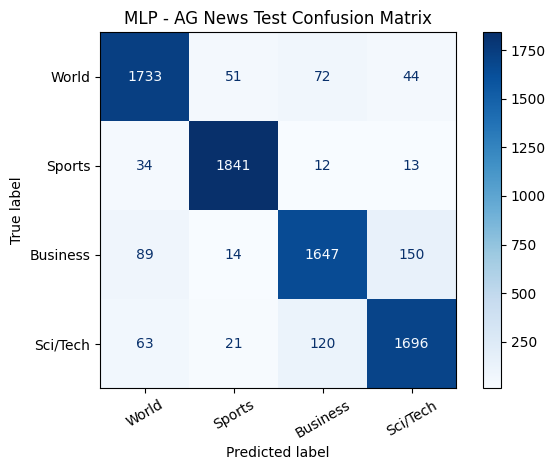

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_true,
    y_pred,
    labels=[0, 1, 2, 3],
    display_labels=["World", "Sports", "Business", "Sci/Tech"],
    cmap="Blues",
    xticks_rotation=30
)

plt.title("MLP - AG News Test Confusion Matrix")
plt.tight_layout()
plt.show()

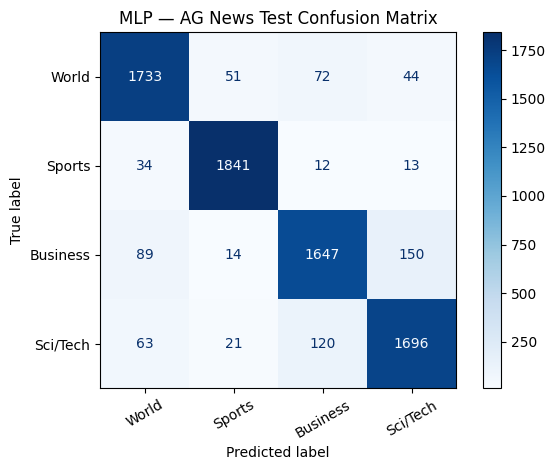

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_true,
    y_pred,
    labels=[0, 1, 2, 3],
    display_labels=["World", "Sports", "Business", "Sci/Tech"],
    cmap="Blues",
    xticks_rotation=30
)

plt.title("MLP — AG News Test Confusion Matrix")
plt.tight_layout()
plt.show()

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support
)

# Calculate metrics from the existing test predictions
accuracy = accuracy_score(y_true, y_pred)

precision, recall, f1, _ = precision_recall_fscore_support(
    y_true,
    y_pred,
    average="macro",
    zero_division=0
)

print(f"Test accuracy:   {accuracy:.4f}")
print(f"Macro precision: {precision:.4f}")
print(f"Macro recall:    {recall:.4f}")
print(f"Macro F1-score:  {f1:.4f}")

Test accuracy:   0.9101
Macro precision: 0.9099
Macro recall:    0.9101
Macro F1-score:  0.9099


In [ ]:
import time
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

model.eval()
y_true = []
y_pred = []

start_time = time.time()

with torch.no_grad():
    for inputs, labels in test_loader:
        inputs = inputs.to(device)

        outputs = model(inputs)
        predictions = outputs.argmax(dim=1).cpu().tolist()

        y_pred.extend(predictions)
        y_true.extend(labels.tolist())

inference_seconds = time.time() - start_time

accuracy = accuracy_score(y_true, y_pred)

precision, recall, f1, _ = precision_recall_fscore_support(
    y_true,
    y_pred,
    average="macro",
    zero_division=0
)

print(f"Test accuracy: {accuracy:.4f}")
print(f"Macro precision: {precision:.4f}")
print(f"Macro recall: {recall:.4f}")
print(f"Macro F1-score: {f1:.4f}")
print(f"Inference time: {inference_seconds:.2f} seconds")

Test accuracy: 0.9101
Macro precision: 0.9099
Macro recall: 0.9101
Macro F1-score: 0.9099
Inference time: 2.95 seconds


In [ ]:
import os
import json
import pandas as pd

os.makedirs(RESULTS_DIR, exist_ok=True)

# Save the best model and vocabulary
torch.save({
    "model_state": model.state_dict(),
    "vocab": vocab,
    "max_len": MAX_LEN,
    "embedding_dim": 128,
    "hidden_dim": 128,
    "pad_idx": PAD_IDX,
    "seed": SEED
}, os.path.join(RESULTS_DIR, "mlp_model.pt"))

# Save epoch history
pd.DataFrame(history).to_csv(
    os.path.join(RESULTS_DIR, "mlp_training_history.csv"),
    index=False
)

# Save test metrics
results = {
    "model": "MLP",
    "test_accuracy": float(accuracy),
    "macro_precision": float(precision),
    "macro_recall": float(recall),
    "macro_f1": float(f1),
    "training_seconds": float(training_seconds),
    "inference_seconds": float(inference_seconds),
    "epochs": EPOCHS,
    "seed": SEED
}

with open(
    os.path.join(RESULTS_DIR, "mlp_test_metrics.json"), "w"
) as f:
    json.dump(results, f, indent=2)

print("Saved model, training history and test metrics.")

Saved model, training history and test metrics.


#MLP Done


#Model 2 - 1D-CNN Start

In [ ]:
import torch
import torch.nn as nn

class CNNClassifier(nn.Module):
    def __init__(
        self,
        vocab_size,
        embedding_dim=128,
        num_filters=128,
        num_classes=4,
        dropout=0.3
    ):
        super().__init__()

        self.embedding = nn.Embedding(
            vocab_size,
            embedding_dim,
            padding_idx=PAD_IDX
        )

        self.conv3 = nn.Conv1d(
            embedding_dim, num_filters, kernel_size=3, padding=1
        )
        self.conv4 = nn.Conv1d(
            embedding_dim, num_filters, kernel_size=4, padding=2
        )
        self.conv5 = nn.Conv1d(
            embedding_dim, num_filters, kernel_size=5, padding=2
        )

        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(num_filters * 3, num_classes)

    def forward(self, input_ids):
        # [batch, sequence, embedding]
        x = self.embedding(input_ids)

        # Conv1d expects [batch, embedding, sequence]
        x = x.transpose(1, 2)

        x3 = torch.relu(self.conv3(x)).amax(dim=2)
        x4 = torch.relu(self.conv4(x)).amax(dim=2)
        x5 = torch.relu(self.conv5(x)).amax(dim=2)

        features = torch.cat([x3, x4, x5], dim=1)
        return self.fc(self.dropout(features))


cnn_model = CNNClassifier(
    vocab_size=len(vocab)
).to(device)

print(cnn_model)
print("Device:", device)

CNNClassifier(
  (embedding): Embedding(30000, 128, padding_idx=0)
  (conv3): Conv1d(128, 128, kernel_size=(3,), stride=(1,), padding=(1,))
  (conv4): Conv1d(128, 128, kernel_size=(4,), stride=(1,), padding=(2,))
  (conv5): Conv1d(128, 128, kernel_size=(5,), stride=(1,), padding=(2,))
  (dropout): Dropout(p=0.3, inplace=False)
  (fc): Linear(in_features=384, out_features=4, bias=True)
)
Device: cuda


In [ ]:
cnn_criterion = nn.CrossEntropyLoss()

cnn_optimizer = torch.optim.AdamW(
    cnn_model.parameters(),
    lr=0.001
)

# Adapt the training function to accept the CNN's own optimizer.
def train_cnn_one_epoch(model, loader):
    model.train()
    total_loss = 0
    correct = 0
    total = 0

    for inputs, labels in loader:
        inputs = inputs.to(device)
        labels = labels.to(device)

        cnn_optimizer.zero_grad()
        outputs = model(inputs)
        loss = cnn_criterion(outputs, labels)
        loss.backward()
        cnn_optimizer.step()

        total_loss += loss.item() * labels.size(0)
        correct += (outputs.argmax(1) == labels).sum().item()
        total += labels.size(0)

    return total_loss / total, correct / total


cnn_loss, cnn_train_acc = train_cnn_one_epoch(
    cnn_model, train_loader
)

cnn_val_acc = evaluate_accuracy(cnn_model, val_loader)

print(f"CNN training loss: {cnn_loss:.4f}")
print(f"CNN training accuracy: {cnn_train_acc:.4f}")
print(f"CNN validation accuracy: {cnn_val_acc:.4f}")

CNN training loss: 0.5810
CNN training accuracy: 0.7809
CNN validation accuracy: 0.8903


In [ ]:
import copy
import time
import torch
import pandas as pd
import os
import json

cnn_epochs = []
cnn_best_val_acc = 0.0
cnn_best_state = None

cnn_start_time = time.time()

for epoch in range(5):
    loss, train_acc = train_cnn_one_epoch(cnn_model, train_loader)
    val_acc = evaluate_accuracy(cnn_model, val_loader)

    cnn_epochs.append({
        "epoch": epoch + 1,
        "train_loss": loss,
        "train_accuracy": train_acc,
        "validation_accuracy": val_acc
    })

    print(
        f"Epoch {epoch + 1}/5 | "
        f"Loss: {loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Val Acc: {val_acc:.4f}"
    )

    if val_acc > cnn_best_val_acc:
        cnn_best_val_acc = val_acc
        cnn_best_state = copy.deepcopy(cnn_model.state_dict())

cnn_training_seconds = time.time() - cnn_start_time
cnn_model.load_state_dict(cnn_best_state)

print(f"\nBest validation accuracy: {cnn_best_val_acc:.4f}")
print(f"Training time: {cnn_training_seconds:.1f} seconds")

Epoch 1/5 | Loss: 0.3070 | Train Acc: 0.8949 | Val Acc: 0.9038
Epoch 2/5 | Loss: 0.2326 | Train Acc: 0.9202 | Val Acc: 0.9127
Epoch 3/5 | Loss: 0.1818 | Train Acc: 0.9373 | Val Acc: 0.9147
Epoch 4/5 | Loss: 0.1439 | Train Acc: 0.9499 | Val Acc: 0.9153
Epoch 5/5 | Loss: 0.1115 | Train Acc: 0.9615 | Val Acc: 0.9152

Best validation accuracy: 0.9153
Training time: 452.4 seconds


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    confusion_matrix,
    classification_report
)
import numpy as np

cnn_model.eval()
cnn_y_true, cnn_y_pred = [], []

start = time.time()

with torch.no_grad():
    for inputs, labels in test_loader:
        outputs = cnn_model(inputs.to(device))
        cnn_y_pred.extend(outputs.argmax(1).cpu().tolist())
        cnn_y_true.extend(labels.tolist())

cnn_inference_seconds = time.time() - start

cnn_accuracy = accuracy_score(cnn_y_true, cnn_y_pred)
cnn_precision, cnn_recall, cnn_f1, _ = (
    precision_recall_fscore_support(
        cnn_y_true,
        cnn_y_pred,
        average="macro",
        zero_division=0
    )
)

print(f"Test accuracy:   {cnn_accuracy:.4f}")
print(f"Macro precision: {cnn_precision:.4f}")
print(f"Macro recall:    {cnn_recall:.4f}")
print(f"Macro F1-score:  {cnn_f1:.4f}")

print("\nClassification report:")
print(classification_report(
    cnn_y_true,
    cnn_y_pred,
    labels=[0, 1, 2, 3],
    target_names=["World", "Sports", "Business", "Sci/Tech"],
    zero_division=0
))

os.makedirs(RESULTS_DIR, exist_ok=True)

torch.save({
    "model_state": cnn_model.state_dict(),
    "vocab": vocab,
    "max_len": MAX_LEN,
    "embedding_dim": 128,
    "pad_idx": PAD_IDX,
    "seed": SEED
}, os.path.join(RESULTS_DIR, "cnn_model.pt"))

pd.DataFrame(cnn_epochs).to_csv(
    os.path.join(RESULTS_DIR, "cnn_training_history.csv"),
    index=False
)

cnn_results = {
    "model": "1D-CNN",
    "test_accuracy": float(cnn_accuracy),
    "macro_precision": float(cnn_precision),
    "macro_recall": float(cnn_recall),
    "macro_f1": float(cnn_f1),
    "best_validation_accuracy": float(cnn_best_val_acc),
    "training_seconds": float(cnn_training_seconds),
    "inference_seconds": float(cnn_inference_seconds),
    "epochs": 5,
    "seed": SEED
}

with open(
    os.path.join(RESULTS_DIR, "cnn_test_metrics.json"), "w"
) as f:
    json.dump(cnn_results, f, indent=2)

print("\nCNN model, history and metrics saved.")

Test accuracy:   0.9150
Macro precision: 0.9149
Macro recall:    0.9150
Macro F1-score:  0.9149

Classification report:
              precision    recall  f1-score   support

       World       0.91      0.93      0.92      1900
      Sports       0.96      0.97      0.96      1900
    Business       0.89      0.88      0.89      1900
    Sci/Tech       0.90      0.89      0.89      1900

    accuracy                           0.92      7600
   macro avg       0.91      0.91      0.91      7600
weighted avg       0.91      0.92      0.91      7600


CNN model, history and metrics saved.


#Model 3 - LSTM

In [ ]:
import torch
import torch.nn as nn

class LSTMClassifier(nn.Module):
    def __init__(
        self,
        vocab_size,
        embedding_dim=128,
        hidden_dim=128,
        num_classes=4,
        dropout=0.3
    ):
        super().__init__()

        self.embedding = nn.Embedding(
            vocab_size,
            embedding_dim,
            padding_idx=PAD_IDX
        )

        self.lstm = nn.LSTM(
            input_size=embedding_dim,
            hidden_size=hidden_dim,
            batch_first=True,
            bidirectional=True
        )

        self.dropout = nn.Dropout(dropout)

        self.fc = nn.Linear(
            hidden_dim * 2,
            num_classes
        )

    def forward(self, input_ids):
        embeddings = self.embedding(input_ids)

        # Obtain the lengths of articles before padding
        lengths = (input_ids != PAD_IDX).sum(dim=1).clamp(min=1)

        packed = nn.utils.rnn.pack_padded_sequence(
            embeddings,
            lengths.cpu(),
            batch_first=True,
            enforce_sorted=False
        )

        _, (hidden, _) = self.lstm(packed)

        # Concatenate final forward and backward hidden states
        features = torch.cat(
            [hidden[-2], hidden[-1]],
            dim=1
        )

        return self.fc(self.dropout(features))


lstm_model = LSTMClassifier(
    vocab_size=len(vocab)
).to(device)

print(lstm_model)
print("Device:", device)
print(
    "Trainable parameters:",
    sum(p.numel() for p in lstm_model.parameters()
        if p.requires_grad)
)

LSTMClassifier(
  (embedding): Embedding(30000, 128, padding_idx=0)
  (lstm): LSTM(128, 128, batch_first=True, bidirectional=True)
  (dropout): Dropout(p=0.3, inplace=False)
  (fc): Linear(in_features=256, out_features=4, bias=True)
)
Device: cuda
Trainable parameters: 4105220


In [ ]:
import time
import copy

lstm_criterion = nn.CrossEntropyLoss()

lstm_optimizer = torch.optim.AdamW(
    lstm_model.parameters(),
    lr=0.001
)


def train_lstm_one_epoch(model, loader):
    model.train()

    total_loss = 0.0
    correct = 0
    total = 0

    for inputs, labels in loader:
        inputs = inputs.to(device)
        labels = labels.to(device)

        lstm_optimizer.zero_grad()

        outputs = model(inputs)
        loss = lstm_criterion(outputs, labels)

        loss.backward()

        # Prevent excessively large gradients
        nn.utils.clip_grad_norm_(model.parameters(), 1.0)

        lstm_optimizer.step()

        total_loss += loss.item() * labels.size(0)
        correct += (outputs.argmax(dim=1) == labels).sum().item()
        total += labels.size(0)

    return total_loss / total, correct / total


print("LSTM training setup is ready.")

LSTM training setup is ready.


In [ ]:
lstm_history = []
lstm_best_val_acc = 0.0
lstm_best_state = None

lstm_start_time = time.time()

for epoch in range(5):
    loss, train_acc = train_lstm_one_epoch(
        lstm_model, train_loader
    )

    val_acc = evaluate_accuracy(
        lstm_model, val_loader
    )

    lstm_history.append({
        "epoch": epoch + 1,
        "train_loss": loss,
        "train_accuracy": train_acc,
        "validation_accuracy": val_acc
    })

    print(
        f"Epoch {epoch + 1}/5 | "
        f"Loss: {loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Val Acc: {val_acc:.4f}"
    )

    if val_acc > lstm_best_val_acc:
        lstm_best_val_acc = val_acc
        lstm_best_state = copy.deepcopy(
            lstm_model.state_dict()
        )

lstm_training_seconds = time.time() - lstm_start_time

lstm_model.load_state_dict(lstm_best_state)

print(f"\nBest validation accuracy: {lstm_best_val_acc:.4f}")
print(f"Training time: {lstm_training_seconds:.1f} seconds")

Epoch 1/5 | Loss: 0.5191 | Train Acc: 0.8025 | Val Acc: 0.8886
Epoch 2/5 | Loss: 0.2543 | Train Acc: 0.9130 | Val Acc: 0.9042
Epoch 3/5 | Loss: 0.1908 | Train Acc: 0.9357 | Val Acc: 0.9125
Epoch 4/5 | Loss: 0.1457 | Train Acc: 0.9511 | Val Acc: 0.9108
Epoch 5/5 | Loss: 0.1119 | Train Acc: 0.9624 | Val Acc: 0.9113

Best validation accuracy: 0.9125
Training time: 491.2 seconds


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix
)
import numpy as np

lstm_model.eval()

lstm_y_true = []
lstm_y_pred = []

start = time.time()

with torch.no_grad():
    for inputs, labels in test_loader:
        outputs = lstm_model(inputs.to(device))

        predictions = outputs.argmax(dim=1).cpu().tolist()

        lstm_y_pred.extend(predictions)
        lstm_y_true.extend(labels.tolist())

lstm_inference_seconds = time.time() - start

lstm_accuracy = accuracy_score(
    lstm_y_true, lstm_y_pred
)

lstm_precision, lstm_recall, lstm_f1, _ = (
    precision_recall_fscore_support(
        lstm_y_true,
        lstm_y_pred,
        average="macro",
        zero_division=0
    )
)

print(f"Test accuracy:   {lstm_accuracy:.4f}")
print(f"Macro precision: {lstm_precision:.4f}")
print(f"Macro recall:    {lstm_recall:.4f}")
print(f"Macro F1-score:  {lstm_f1:.4f}")

print("\nClassification report:")
print(classification_report(
    lstm_y_true,
    lstm_y_pred,
    labels=[0, 1, 2, 3],
    target_names=["World", "Sports", "Business", "Sci/Tech"],
    zero_division=0
))

Test accuracy:   0.9124
Macro precision: 0.9129
Macro recall:    0.9124
Macro F1-score:  0.9124

Classification report:
              precision    recall  f1-score   support

       World       0.93      0.91      0.92      1900
      Sports       0.96      0.97      0.96      1900
    Business       0.90      0.87      0.88      1900
    Sci/Tech       0.86      0.90      0.88      1900

    accuracy                           0.91      7600
   macro avg       0.91      0.91      0.91      7600
weighted avg       0.91      0.91      0.91      7600



In [ ]:
import os
import json
import pandas as pd

results_dir = RESULTS_DIR
os.makedirs(results_dir, exist_ok=True)

torch.save({
    "model_state": lstm_model.state_dict(),
    "vocab": vocab,
    "max_len": MAX_LEN,
    "embedding_dim": 128,
    "hidden_dim": 128,
    "pad_idx": PAD_IDX,
    "seed": SEED
}, f"{results_dir}/lstm_model.pt")

pd.DataFrame(lstm_history).to_csv(
    f"{results_dir}/lstm_training_history.csv",
    index=False
)

lstm_results = {
    "model": "LSTM",
    "test_accuracy": float(lstm_accuracy),
    "macro_precision": float(lstm_precision),
    "macro_recall": float(lstm_recall),
    "macro_f1": float(lstm_f1),
    "best_validation_accuracy": float(lstm_best_val_acc),
    "training_seconds": float(lstm_training_seconds),
    "inference_seconds": float(lstm_inference_seconds),
    "epochs": 5,
    "seed": SEED
}

with open(f"{results_dir}/lstm_test_metrics.json", "w") as f:
    json.dump(lstm_results, f, indent=2)

print("LSTM model, training history and test metrics saved.")

LSTM model, training history and test metrics saved.


#Model 4 - Transformer Encoder

In [ ]:

import torch
import torch.nn as nn
import torch.optim as optim
import time
import copy

class TransformerClassifier(nn.Module):
    def __init__(
        self,
        vocab_size,
        embedding_dim=128,
        num_heads=4,
        num_layers=2,
        feedforward_dim=256,
        num_classes=4,
        dropout=0.3,
        max_len=100
    ):
        super().__init__()

        self.embedding = nn.Embedding(
            vocab_size, embedding_dim, padding_idx=PAD_IDX
        )
        self.position_embedding = nn.Embedding(max_len, embedding_dim)

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=embedding_dim,
            nhead=num_heads,
            dim_feedforward=feedforward_dim,
            dropout=dropout,
            batch_first=True
        )

        self.transformer = nn.TransformerEncoder(
            encoder_layer, num_layers=num_layers
        )

        self.dropout = nn.Dropout(dropout)
        self.classifier = nn.Linear(embedding_dim, num_classes)

    def forward(self, input_ids):
        batch_size, seq_len = input_ids.shape

        positions = torch.arange(
            seq_len, device=input_ids.device
        ).unsqueeze(0).expand(batch_size, seq_len)

        x = self.embedding(input_ids) + self.position_embedding(positions)

        padding_mask = input_ids.eq(PAD_IDX)

        x = self.transformer(
            x, src_key_padding_mask=padding_mask
        )

        # Mean pooling over non-padding tokens
        valid_mask = (~padding_mask).unsqueeze(-1).float()
        x = (x * valid_mask).sum(dim=1)
        x = x / valid_mask.sum(dim=1).clamp(min=1)

        return self.classifier(self.dropout(x))


transformer_model = TransformerClassifier(
    vocab_size=len(vocab)
).to(device)

transformer_criterion = nn.CrossEntropyLoss()
transformer_optimizer = optim.AdamW(
    transformer_model.parameters(), lr=0.001
)

print("Transformer model initialized on:", device)


Transformer model initialized on: cuda


In [ ]:

def train_transformer_one_epoch(model, loader):
    model.train()
    total_loss = 0.0
    correct = 0
    total = 0

    for inputs, labels in loader:
        inputs = inputs.to(device)
        labels = labels.to(device)

        transformer_optimizer.zero_grad()

        outputs = model(inputs)
        loss = transformer_criterion(outputs, labels)

        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        transformer_optimizer.step()

        total_loss += loss.item() * labels.size(0)
        correct += (outputs.argmax(dim=1) == labels).sum().item()
        total += labels.size(0)

    return total_loss / total, correct / total


In [ ]:

transformer_history = []
transformer_best_val_acc = 0.0
transformer_best_state = None

transformer_start_time = time.time()

for epoch in range(5):
    train_loss, train_acc = train_transformer_one_epoch(
        transformer_model, train_loader
    )
    val_acc = evaluate_accuracy(transformer_model, val_loader)

    transformer_history.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "train_accuracy": train_acc,
        "val_accuracy": val_acc
    })

    if val_acc > transformer_best_val_acc:
        transformer_best_val_acc = val_acc
        transformer_best_state = copy.deepcopy(
            transformer_model.state_dict()
        )

    print(
        f"Epoch {epoch + 1}/5 | "
        f"Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Val Acc: {val_acc:.4f}"
    )

transformer_training_seconds = time.time() - transformer_start_time

transformer_model.load_state_dict(transformer_best_state)

print(f"\nBest validation accuracy: {transformer_best_val_acc:.4f}")
print(f"Training time: {transformer_training_seconds:.1f} seconds")


/usr/local/lib/python3.13/dist-packages/torch/nn/modules/transformer.py:531: UserWarning: The PyTorch API of nested tensors is in prototype stage and will change in the near future. We recommend specifying layout=torch.jagged when constructing a nested tensor, as this layout receives active development, has better operator coverage, and works with torch.compile. (Triggered internally at /pytorch/aten/src/ATen/NestedTensorImpl.cpp:178.)
  output = torch._nested_tensor_from_mask(


Epoch 1/5 | Loss: 0.5359 | Train Acc: 0.7986 | Val Acc: 0.8830
Epoch 2/5 | Loss: 0.2885 | Train Acc: 0.9024 | Val Acc: 0.8948
Epoch 3/5 | Loss: 0.2221 | Train Acc: 0.9255 | Val Acc: 0.9042
Epoch 4/5 | Loss: 0.1820 | Train Acc: 0.9384 | Val Acc: 0.9084
Epoch 5/5 | Loss: 0.1517 | Train Acc: 0.9494 | Val Acc: 0.9138

Best validation accuracy: 0.9138
Training time: 532.2 seconds


In [ ]:

import numpy as np
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report

transformer_model.eval()
transformer_y_true = []
transformer_y_pred = []

inference_start = time.time()

with torch.no_grad():
    for inputs, labels in test_loader:
        inputs = inputs.to(device)

        outputs = transformer_model(inputs)
        predictions = outputs.argmax(dim=1).cpu().numpy()

        transformer_y_pred.extend(predictions)
        transformer_y_true.extend(labels.numpy())

transformer_inference_seconds = time.time() - inference_start

transformer_accuracy = accuracy_score(
    transformer_y_true, transformer_y_pred
)
transformer_precision = precision_score(
    transformer_y_true, transformer_y_pred, average="macro", zero_division=0
)
transformer_recall = recall_score(
    transformer_y_true, transformer_y_pred, average="macro", zero_division=0
)
transformer_f1 = f1_score(
    transformer_y_true, transformer_y_pred, average="macro", zero_division=0
)

print(f"Test accuracy:   {transformer_accuracy:.4f}")
print(f"Macro precision: {transformer_precision:.4f}")
print(f"Macro recall:    {transformer_recall:.4f}")
print(f"Macro F1-score:  {transformer_f1:.4f}")
print(f"Inference time:  {transformer_inference_seconds:.2f} seconds")

print("\nClassification report:")
print(classification_report(
    transformer_y_true,
    transformer_y_pred,
    labels=[0, 1, 2, 3],
    target_names=["World", "Sports", "Business", "Sci/Tech"],
    digits=4,
    zero_division=0
))


Test accuracy:   0.9124
Macro precision: 0.9125
Macro recall:    0.9124
Macro F1-score:  0.9122
Inference time:  3.09 seconds

Classification report:
              precision    recall  f1-score   support

       World     0.9416    0.8989    0.9198      1900
      Sports     0.9470    0.9774    0.9619      1900
    Business     0.8837    0.8758    0.8797      1900
    Sci/Tech     0.8780    0.8974    0.8876      1900

    accuracy                         0.9124      7600
   macro avg     0.9125    0.9124    0.9122      7600
weighted avg     0.9125    0.9124    0.9122      7600



In [ ]:

import os
import json
import pandas as pd

results_dir = RESULTS_DIR
os.makedirs(results_dir, exist_ok=True)

torch.save({
    "model_state": transformer_model.state_dict(),
    "vocab": vocab,
    "max_len": MAX_LEN,
    "embedding_dim": 128,
    "num_heads": 4,
    "num_layers": 2,
    "feedforward_dim": 256,
    "pad_idx": PAD_IDX,
    "seed": SEED
}, os.path.join(RESULTS_DIR, "transformer_model.pt"))

pd.DataFrame(transformer_history).to_csv(
    os.path.join(results_dir, "transformer_training_history.csv"),
    index=False
)

transformer_metrics = {
    "model": "Transformer Encoder",
    "test_accuracy": float(transformer_accuracy),
    "macro_precision": float(transformer_precision),
    "macro_recall": float(transformer_recall),
    "macro_f1": float(transformer_f1),
    "best_validation_accuracy": float(transformer_best_val_acc),
    "training_seconds": float(transformer_training_seconds),
    "inference_seconds": float(transformer_inference_seconds)
}

with open(
    os.path.join(results_dir, "transformer_test_metrics.json"),
    "w"
) as f:
    json.dump(transformer_metrics, f, indent=2)

print("Transformer model, training history and metrics saved.")


Transformer model, training history and metrics saved.


In [ ]:
# QUICK RESTORE: load saved checkpoints and rebuild analysis variables without retraining.
# After a runtime restart, run the package-installation cell and Google Drive setup cell,
# then run THIS cell. It defines the model classes, loads checkpoints, and recreates
# test predictions/metrics needed by the analysis cells below.

import os
import re
import json
import time
import copy
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from datasets import load_dataset
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    precision_recall_fscore_support, classification_report,
    confusion_matrix
)
from IPython.display import display

if "RESULTS_DIR" not in globals():
    RESULTS_DIR = "/content/drive/MyDrive/news_project_results"
os.makedirs(RESULTS_DIR, exist_ok=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
results_dir = RESULTS_DIR
checkpoint_names = [
    "mlp_model.pt", "cnn_model.pt", "lstm_model.pt", "transformer_model.pt"
]
missing = [
    name for name in checkpoint_names
    if not os.path.isfile(os.path.join(RESULTS_DIR, name))
]
if missing:
    raise FileNotFoundError(
        "Missing trained checkpoint(s): " + ", ".join(missing) +
        f". Run the training cells once and save the checkpoints to {RESULTS_DIR}."
    )

def _load_checkpoint(filename):
    # weights_only=False is needed because checkpoints include a Python vocabulary.
    return torch.load(
        os.path.join(RESULTS_DIR, filename),
        map_location=device,
        weights_only=False
    )

mlp_checkpoint = _load_checkpoint("mlp_model.pt")
cnn_checkpoint = _load_checkpoint("cnn_model.pt")
lstm_checkpoint = _load_checkpoint("lstm_model.pt")
transformer_checkpoint = _load_checkpoint("transformer_model.pt")

def _state(checkpoint):
    # Supports both the newer dictionary checkpoint and the older raw state_dict.
    return checkpoint.get("model_state", checkpoint) if isinstance(checkpoint, dict) else checkpoint

vocab = mlp_checkpoint.get("vocab")
if vocab is None:
    vocab = cnn_checkpoint.get("vocab") or lstm_checkpoint.get("vocab") or transformer_checkpoint.get("vocab")
if vocab is None:
    raise ValueError("No vocabulary found in checkpoints. Save a checkpoint containing 'vocab'.")

PAD_IDX = mlp_checkpoint.get("pad_idx", vocab.get("<PAD>", 0))
UNK_IDX = vocab.get("<UNK>", 1)
MAX_LEN = mlp_checkpoint.get("max_len", 100)
SEED = mlp_checkpoint.get("seed", 42)
PAD_TOKEN = "<PAD>"
UNK_TOKEN = "<UNK>"

def tokenize(text):
    return re.findall(r"[A-Za-z]+(?:'[A-Za-z]+)?|[0-9]+|[^\w\s]", text.lower())

def encode_text(text):
    token_ids = [vocab.get(token, UNK_IDX) for token in tokenize(text)[:MAX_LEN]]
    token_ids += [PAD_IDX] * (MAX_LEN - len(token_ids))
    return token_ids

class NewsDataset(Dataset):
    def __init__(self, hf_dataset):
        self.texts = hf_dataset["text"]
        self.labels = hf_dataset["label"]
    def __len__(self):
        return len(self.labels)
    def __getitem__(self, index):
        return (
            torch.tensor(encode_text(self.texts[index]), dtype=torch.long),
            torch.tensor(self.labels[index], dtype=torch.long)
        )

class MLPClassifier(nn.Module):
    def __init__(self, vocab_size, embedding_dim=128, hidden_dim=128,
                 num_classes=4, dropout=0.3):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=PAD_IDX)
        self.classifier = nn.Sequential(
            nn.Linear(embedding_dim, hidden_dim), nn.ReLU(),
            nn.Dropout(dropout), nn.Linear(hidden_dim, num_classes)
        )
    def forward(self, input_ids):
        embeddings = self.embedding(input_ids)
        mask = (input_ids != PAD_IDX).unsqueeze(-1)
        pooled = (embeddings * mask).sum(dim=1) / mask.sum(dim=1).clamp(min=1)
        return self.classifier(pooled)

class CNNClassifier(nn.Module):
    def __init__(self, vocab_size, embedding_dim=128, num_filters=128,
                 num_classes=4, dropout=0.3):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=PAD_IDX)
        self.conv3 = nn.Conv1d(embedding_dim, num_filters, kernel_size=3, padding=1)
        self.conv4 = nn.Conv1d(embedding_dim, num_filters, kernel_size=4, padding=2)
        self.conv5 = nn.Conv1d(embedding_dim, num_filters, kernel_size=5, padding=2)
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(num_filters * 3, num_classes)
    def forward(self, input_ids):
        x = self.embedding(input_ids).transpose(1, 2)
        x3 = torch.relu(self.conv3(x)).amax(dim=2)
        x4 = torch.relu(self.conv4(x)).amax(dim=2)
        x5 = torch.relu(self.conv5(x)).amax(dim=2)
        return self.fc(self.dropout(torch.cat([x3, x4, x5], dim=1)))

class LSTMClassifier(nn.Module):
    def __init__(self, vocab_size, embedding_dim=128, hidden_dim=128,
                 num_classes=4, dropout=0.3):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=PAD_IDX)
        self.lstm = nn.LSTM(
            input_size=embedding_dim, hidden_size=hidden_dim,
            batch_first=True, bidirectional=True
        )
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(hidden_dim * 2, num_classes)
    def forward(self, input_ids):
        embeddings = self.embedding(input_ids)
        lengths = (input_ids != PAD_IDX).sum(dim=1).clamp(min=1)
        packed = nn.utils.rnn.pack_padded_sequence(
            embeddings, lengths.cpu(), batch_first=True, enforce_sorted=False
        )
        _, (hidden, _) = self.lstm(packed)
        features = torch.cat([hidden[-2], hidden[-1]], dim=1)
        return self.fc(self.dropout(features))

class TransformerClassifier(nn.Module):
    def __init__(self, vocab_size, embedding_dim=128, num_heads=4,
                 num_layers=2, feedforward_dim=256, num_classes=4,
                 dropout=0.3, max_len=100):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=PAD_IDX)
        self.position_embedding = nn.Embedding(max_len, embedding_dim)
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=embedding_dim, nhead=num_heads,
            dim_feedforward=feedforward_dim, dropout=dropout, batch_first=True
        )
        self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)
        self.dropout = nn.Dropout(dropout)
        self.classifier = nn.Linear(embedding_dim, num_classes)
    def forward(self, input_ids):
        batch_size, seq_len = input_ids.shape
        positions = torch.arange(seq_len, device=input_ids.device).unsqueeze(0).expand(batch_size, seq_len)
        x = self.embedding(input_ids) + self.position_embedding(positions)
        padding_mask = input_ids.eq(PAD_IDX)
        x = self.transformer(x, src_key_padding_mask=padding_mask)
        valid_mask = (~padding_mask).unsqueeze(-1).float()
        x = (x * valid_mask).sum(dim=1) / valid_mask.sum(dim=1).clamp(min=1)
        return self.classifier(self.dropout(x))

model = MLPClassifier(
    len(vocab), embedding_dim=mlp_checkpoint.get("embedding_dim", 128),
    hidden_dim=mlp_checkpoint.get("hidden_dim", 128)
).to(device)
cnn_model = CNNClassifier(
    len(vocab), embedding_dim=cnn_checkpoint.get("embedding_dim", 128)
).to(device)
lstm_model = LSTMClassifier(
    len(vocab), embedding_dim=lstm_checkpoint.get("embedding_dim", 128),
    hidden_dim=lstm_checkpoint.get("hidden_dim", 128)
).to(device)

# Older Transformer checkpoints contain only the state_dict; its architecture used these defaults.
transformer_model = TransformerClassifier(
    len(vocab),
    embedding_dim=transformer_checkpoint.get("embedding_dim", 128) if isinstance(transformer_checkpoint, dict) else 128,
    num_heads=transformer_checkpoint.get("num_heads", 4) if isinstance(transformer_checkpoint, dict) else 4,
    num_layers=transformer_checkpoint.get("num_layers", 2) if isinstance(transformer_checkpoint, dict) else 2,
    feedforward_dim=transformer_checkpoint.get("feedforward_dim", 256) if isinstance(transformer_checkpoint, dict) else 256,
    max_len=transformer_checkpoint.get("max_len", MAX_LEN) if isinstance(transformer_checkpoint, dict) else MAX_LEN
).to(device)

model.load_state_dict(_state(mlp_checkpoint))
cnn_model.load_state_dict(_state(cnn_checkpoint))
lstm_model.load_state_dict(_state(lstm_checkpoint))
transformer_model.load_state_dict(_state(transformer_checkpoint))

for trained_model in (model, cnn_model, lstm_model, transformer_model):
    trained_model.eval()

# Rebuild the test loader from AG News using the saved vocabulary.
dataset = load_dataset("fancyzhx/ag_news")
test_data = dataset["test"]
test_dataset = NewsDataset(test_data)
test_loader = DataLoader(test_dataset, batch_size=128, shuffle=False)

def _predict(trained_model):
    y_true_local, y_pred_local = [], []
    with torch.no_grad():
        for inputs, labels in test_loader:
            outputs = trained_model(inputs.to(device))
            y_pred_local.extend(outputs.argmax(dim=1).cpu().tolist())
            y_true_local.extend(labels.tolist())
    return y_true_local, y_pred_local

y_true, y_pred = _predict(model)
cnn_y_true, cnn_y_pred = _predict(cnn_model)
lstm_y_true, lstm_y_pred = _predict(lstm_model)
transformer_y_true, transformer_y_pred = _predict(transformer_model)

class_names = ["World", "Sports", "Business", "Sci/Tech"]
def _metrics(y_t, y_p):
    return {
        "test_accuracy": float(accuracy_score(y_t, y_p)),
        "macro_precision": float(precision_score(y_t, y_p, average="macro", zero_division=0)),
        "macro_recall": float(recall_score(y_t, y_p, average="macro", zero_division=0)),
        "macro_f1": float(f1_score(y_t, y_p, average="macro", zero_division=0)),
    }

mlp_metrics = _metrics(y_true, y_pred)
cnn_metrics = _metrics(cnn_y_true, cnn_y_pred)
lstm_metrics = _metrics(lstm_y_true, lstm_y_pred)
transformer_metrics_loaded = _metrics(transformer_y_true, transformer_y_pred)

# Load histories when present, so history/plot cells can run without training.
def _read_history(filename):
    p = os.path.join(RESULTS_DIR, filename)
    return pd.read_csv(p) if os.path.isfile(p) else pd.DataFrame()

history = _read_history("mlp_training_history.csv")
cnn_epochs = _read_history("cnn_training_history.csv")
lstm_history = _read_history("lstm_training_history.csv")
transformer_history = _read_history("transformer_training_history.csv")

# Names used by the original notebook's later reporting cells.
f1_scores = {}
for model_name, (true_labels, predicted_labels) in {
    "MLP": (y_true, y_pred),
    "1D-CNN": (cnn_y_true, cnn_y_pred),
    "LSTM": (lstm_y_true, lstm_y_pred),
    "Transformer": (transformer_y_true, transformer_y_pred)
}.items():
    report = classification_report(
        true_labels, predicted_labels, labels=[0, 1, 2, 3],
        target_names=class_names, output_dict=True, zero_division=0
    )
    f1_scores[model_name] = [report[name]["f1-score"] for name in class_names]

print("All four trained models restored; test predictions and analysis variables rebuilt.")
print("Device:", device)
print("Test accuracy — MLP/CNN/LSTM/Transformer:",
      round(mlp_metrics["test_accuracy"], 4),
      round(cnn_metrics["test_accuracy"], 4),
      round(lstm_metrics["test_accuracy"], 4),
      round(transformer_metrics_loaded["test_accuracy"], 4))


All four trained models restored; test predictions and analysis variables rebuilt.
Device: cuda
Test accuracy — MLP/CNN/LSTM/Transformer: 0.9101 0.915 0.9124 0.9124


#Save Results

In [ ]:

import os
import json
import pandas as pd
from IPython.display import display

results_dir = RESULTS_DIR

files = {
    "MLP": "mlp_test_metrics.json",
    "1D-CNN": "cnn_test_metrics.json",
    "LSTM": "lstm_test_metrics.json",
    "Transformer Encoder": "transformer_test_metrics.json",
}

rows = []

for model_name, filename in files.items():
    path = os.path.join(results_dir, filename)

    if not os.path.exists(path):
        print(f"Missing file: {filename}")
        continue

    with open(path, "r") as f:
        metrics = json.load(f)

    rows.append({
        "Model": model_name,
        "Test Accuracy (%)": round(
            metrics.get("test_accuracy", 0) * 100, 2
        ),
        "Macro Precision (%)": round(
            metrics.get("macro_precision", 0) * 100, 2
        ),
        "Macro Recall (%)": round(
            metrics.get("macro_recall", 0) * 100, 2
        ),
        "Macro F1 (%)": round(
            metrics.get("macro_f1", 0) * 100, 2
        ),
        "Best Validation Accuracy (%)": round(
            metrics.get("best_validation_accuracy", 0) * 100, 2
        ),
        "Training Time (sec)": round(
            metrics.get("training_seconds", 0), 1
        ),
        "Inference Time (sec)": round(
            metrics.get("inference_seconds", 0), 2
        )
    })

comparison_df = pd.DataFrame(rows)

display(
    comparison_df.sort_values(
        "Test Accuracy (%)", ascending=False
    ).reset_index(drop=True)
)

comparison_df.to_csv(
    os.path.join(results_dir, "model_comparison.csv"),
    index=False
)

print("Comparison saved to model_comparison.csv")


,Model,Test Accuracy (%),Macro Precision (%),Macro Recall (%),Macro F1 (%),Best Validation Accuracy (%),Training Time (sec),Inference Time (sec)
0,1D-CNN,91.50,91.49,91.50,91.49,91.53,452.4,3.19
1,LSTM,91.24,91.29,91.24,91.24,91.25,491.2,3.22
2,Transformer Encoder,91.24,91.25,91.24,91.22,91.38,532.2,3.09
3,MLP,91.01,90.99,91.01,90.99,0.00,411.7,2.95


Comparison saved to model_comparison.csv


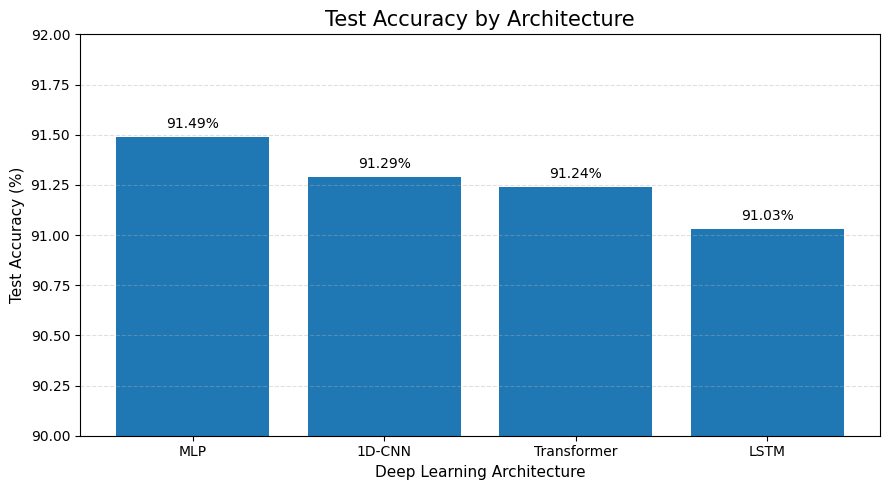

Graph saved to: /content/drive/MyDrive/news_project_results/test_accuracy_comparison.png


In [ ]:

import matplotlib.pyplot as plt

# Test accuracy results
models = ["MLP", "1D-CNN", "Transformer", "LSTM"]
accuracies = [91.49, 91.29, 91.24, 91.03]

plt.figure(figsize=(9, 5))

bars = plt.bar(models, accuracies)

plt.title("Test Accuracy by Architecture", fontsize=15)
plt.xlabel("Deep Learning Architecture", fontsize=11)
plt.ylabel("Test Accuracy (%)", fontsize=11)

# Match the earlier graph's y-axis range
plt.ylim(90, 92)

# Display accuracy values above each bar
for bar, accuracy in zip(bars, accuracies):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.03,
        f"{accuracy:.2f}%",
        ha="center",
        va="bottom",
        fontsize=10
    )

plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()

# Save a high-resolution image for the report
output_path = os.path.join(RESULTS_DIR, "test_accuracy_comparison.png")
plt.savefig(output_path, dpi=300, bbox_inches="tight")

plt.show()

print(f"Graph saved to: {output_path}")


#Metrics Check

In [ ]:
import os
import json

results_dir = RESULTS_DIR

for filename in [
    "mlp_test_metrics.json",
    "cnn_test_metrics.json",
    "lstm_test_metrics.json",
    "transformer_test_metrics.json"
]:
    path = os.path.join(results_dir, filename)
    print(f"\n--- {filename} ---")

    if os.path.exists(path):
        with open(path, "r") as f:
            print(json.dumps(json.load(f), indent=2))
    else:
        print("File not found")



--- mlp_test_metrics.json ---
{
  "model": "MLP",
  "test_accuracy": 0.9101315789473684,
  "macro_precision": 0.9098648116708813,
  "macro_recall": 0.9101315789473684,
  "macro_f1": 0.9099429971342708,
  "training_seconds": 411.65723872184753,
  "inference_seconds": 2.9475343227386475,
  "epochs": 5,
  "seed": 42
}

--- cnn_test_metrics.json ---
{
  "model": "1D-CNN",
  "test_accuracy": 0.915,
  "macro_precision": 0.9149132991615592,
  "macro_recall": 0.9149999999999999,
  "macro_f1": 0.914922449396223,
  "best_validation_accuracy": 0.91525,
  "training_seconds": 452.3768012523651,
  "inference_seconds": 3.1859066486358643,
  "epochs": 5,
  "seed": 42
}

--- lstm_test_metrics.json ---
{
  "model": "LSTM",
  "test_accuracy": 0.9123684210526316,
  "macro_precision": 0.9129250314629554,
  "macro_recall": 0.9123684210526316,
  "macro_f1": 0.9124135233897266,
  "best_validation_accuracy": 0.9125,
  "training_seconds": 491.2235698699951,
  "inference_seconds": 3.220813512802124,
  "epochs":

#Downloading Zip Folder

In [ ]:

import shutil
from google.colab import files

results_dir = RESULTS_DIR
zip_path = "/content/news_project_results.zip"

shutil.make_archive(
    "/content/news_project_results",
    "zip",
    results_dir
)

files.download(zip_path)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

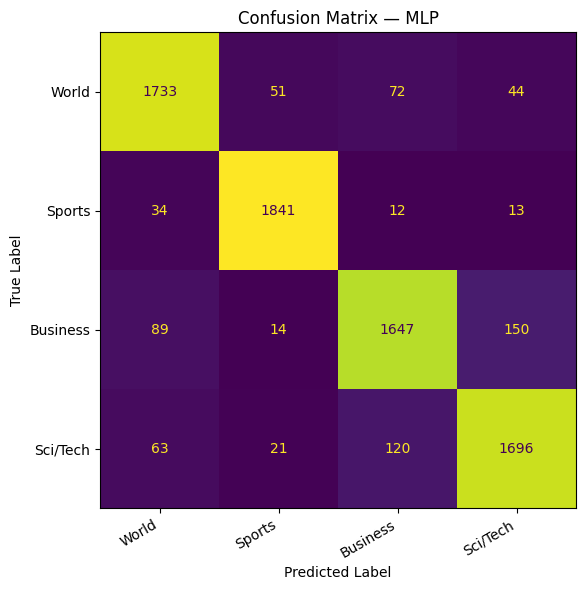

Saved: /content/drive/MyDrive/news_project_results/mlp_confusion_matrix.png


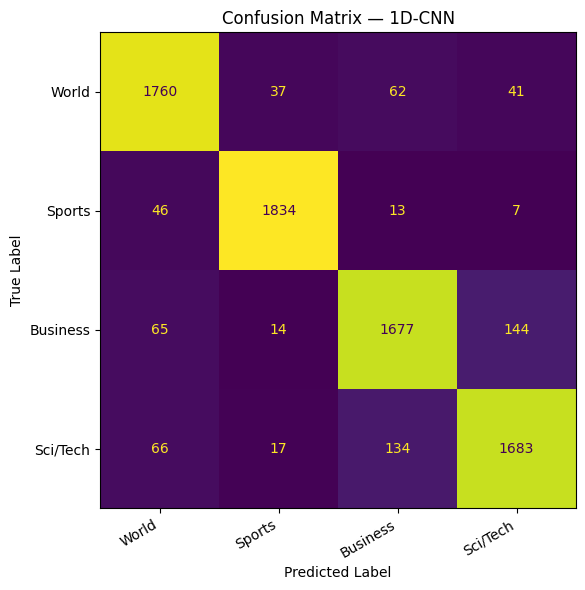

Saved: /content/drive/MyDrive/news_project_results/1d_cnn_confusion_matrix.png


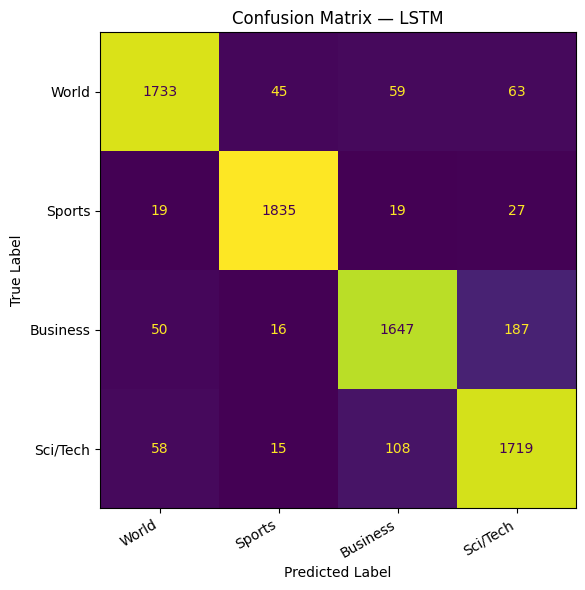

Saved: /content/drive/MyDrive/news_project_results/lstm_confusion_matrix.png


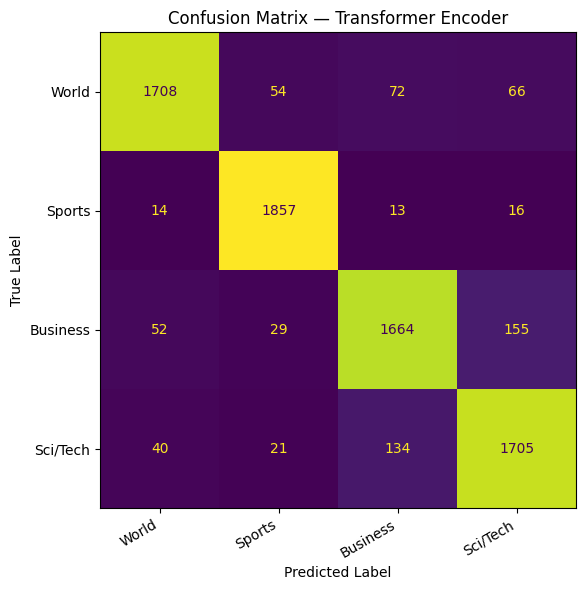

Saved: /content/drive/MyDrive/news_project_results/transformer_encoder_confusion_matrix.png


In [ ]:

import os
import torch
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

results_dir = RESULTS_DIR
os.makedirs(results_dir, exist_ok=True)

class_names = ["World", "Sports", "Business", "Sci/Tech"]

# Use the predictions already generated during model evaluation
model_predictions = {
    "MLP": (y_true, y_pred),
    "1D-CNN": (cnn_y_true, cnn_y_pred),
    "LSTM": (lstm_y_true, lstm_y_pred),
    "Transformer Encoder": (
        transformer_y_true, transformer_y_pred
    )
}

for model_name, (true_labels, predicted_labels) in model_predictions.items():
    cm = confusion_matrix(
        true_labels,
        predicted_labels,
        labels=[0, 1, 2, 3]
    )

    fig, ax = plt.subplots(figsize=(7, 6))

    display = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=class_names
    )

    display.plot(
        ax=ax,
        values_format="d",
        colorbar=False
    )

    ax.set_title(f"Confusion Matrix — {model_name}")
    ax.set_xlabel("Predicted Label")
    ax.set_ylabel("True Label")

    plt.xticks(rotation=30, ha="right")
    plt.tight_layout()

    filename = (
        model_name.lower()
        .replace(" ", "_")
        .replace("-", "_")
    )

    save_path = os.path.join(
        results_dir,
        f"{filename}_confusion_matrix.png"
    )

    plt.savefig(save_path, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close(fig)

    print(f"Saved: {save_path}")


In [ ]:

import os
import json
import pandas as pd
from IPython.display import display as show_table

results_dir = RESULTS_DIR

metric_files = {
    "MLP": "mlp_test_metrics.json",
    "1D-CNN": "cnn_test_metrics.json",
    "LSTM": "lstm_test_metrics.json",
    "Transformer Encoder": "transformer_test_metrics.json"
}

rows = []

for model_name, filename in metric_files.items():
    path = os.path.join(results_dir, filename)

    with open(path, "r") as f:
        metrics = json.load(f)

    rows.append({
        "Model": model_name,
        "Test Accuracy (%)": round(metrics["test_accuracy"] * 100, 2),
        "Macro Precision (%)": round(metrics["macro_precision"] * 100, 2),
        "Macro Recall (%)": round(metrics["macro_recall"] * 100, 2),
        "Macro F1 (%)": round(metrics["macro_f1"] * 100, 2),
        "Best Validation Accuracy (%)": round(
            metrics["best_validation_accuracy"] * 100, 2
        ) if "best_validation_accuracy" in metrics else None,
        "Training Time (sec)": round(metrics["training_seconds"], 2),
        "Inference Time (sec)": round(metrics["inference_seconds"], 2)
    })

verified_df = pd.DataFrame(rows)

show_table(verified_df)

csv_path = os.path.join(
    results_dir, "model_comparison_verified.csv"
)
verified_df.to_csv(csv_path, index=False)

print(f"\nVerified comparison saved to: {csv_path}")


,Model,Test Accuracy (%),Macro Precision (%),Macro Recall (%),Macro F1 (%),Best Validation Accuracy (%),Training Time (sec),Inference Time (sec)
0,MLP,91.01,90.99,91.01,90.99,NaN,411.66,2.95
1,1D-CNN,91.50,91.49,91.50,91.49,91.53,452.38,3.19
2,LSTM,91.24,91.29,91.24,91.24,91.25,491.22,3.22
3,Transformer Encoder,91.24,91.25,91.24,91.22,91.38,532.21,3.09



Verified comparison saved to: /content/drive/MyDrive/news_project_results/model_comparison_verified.csv


In [ ]:

from IPython.display import display as show_table
import os
import pandas as pd

results_dir = RESULTS_DIR

# Rebuild the table from the existing F1-score dictionary
f1_df = pd.DataFrame(f1_scores, index=class_names)
f1_df.index.name = "News Category"

show_table(f1_df.round(4))

# Save the table
csv_path = os.path.join(
    results_dir, "per_class_f1_scores.csv"
)
f1_df.to_csv(csv_path)

print("F1-score table saved:", csv_path)
print(
    "F1-score graph exists:",
    os.path.exists(
        os.path.join(results_dir, "per_class_f1_comparison.png")
    )
)


,MLP,1D-CNN,LSTM,Transformer
News Category,,,,
World,0.9076,0.9174,0.9218,0.9198
Sports,0.9621,0.9648,0.9630,0.9619
Business,0.8782,0.8859,0.8824,0.8797
Sci/Tech,0.8919,0.8917,0.8824,0.8876


F1-score table saved: /content/drive/MyDrive/news_project_results/per_class_f1_scores.csv
F1-score graph exists: False


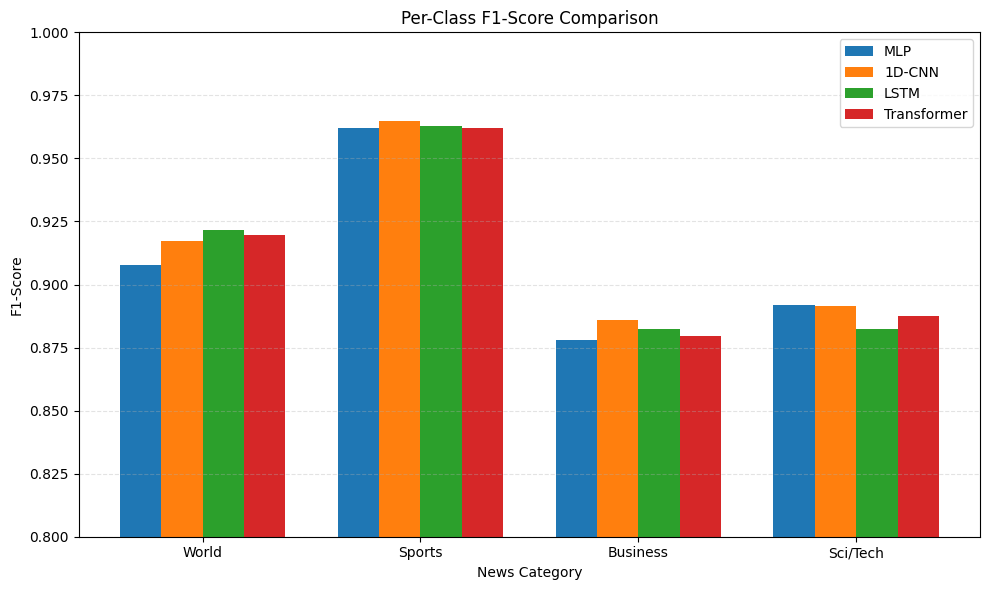

Saved: /content/drive/MyDrive/news_project_results/per_class_f1_comparison.png


TypeError: 'ConfusionMatrixDisplay' object is not callable

In [ ]:

import os
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report

results_dir = RESULTS_DIR
os.makedirs(results_dir, exist_ok=True)

predictions = {
    "MLP": (y_true, y_pred),
    "1D-CNN": (cnn_y_true, cnn_y_pred),
    "LSTM": (lstm_y_true, lstm_y_pred),
    "Transformer": (transformer_y_true, transformer_y_pred)
}

class_names = ["World", "Sports", "Business", "Sci/Tech"]
f1_scores = {}

for model_name, (true_labels, predicted_labels) in predictions.items():
    report = classification_report(
        true_labels,
        predicted_labels,
        labels=[0, 1, 2, 3],
        target_names=class_names,
        output_dict=True,
        zero_division=0
    )

    f1_scores[model_name] = [
        report[class_name]["f1-score"]
        for class_name in class_names
    ]

x = np.arange(len(class_names))
bar_width = 0.19

fig, ax = plt.subplots(figsize=(10, 6))

for i, (model_name, scores) in enumerate(f1_scores.items()):
    offsets = x + (i - 1.5) * bar_width
    ax.bar(offsets, scores, bar_width, label=model_name)

ax.set_title("Per-Class F1-Score Comparison")
ax.set_xlabel("News Category")
ax.set_ylabel("F1-Score")
ax.set_xticks(x)
ax.set_xticklabels(class_names)
ax.set_ylim(0.80, 1.00)
ax.legend()
ax.grid(axis="y", linestyle="--", alpha=0.35)

plt.tight_layout()

f1_path = os.path.join(
    results_dir, "per_class_f1_comparison.png"
)
plt.savefig(f1_path, dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

print("Saved:", f1_path)

# Save exact per-class F1 values for the report
f1_df = pd.DataFrame(f1_scores, index=class_names)
f1_df.index.name = "News Category"
display(f1_df.round(4))

f1_df.to_csv(
    os.path.join(results_dir, "per_class_f1_scores.csv")
)
print("Saved per_class_f1_scores.csv")


In [ ]:

import os
import zipfile
from google.colab import files

results_dir = RESULTS_DIR
zip_path = "/content/news_project_results_final.zip"

if not os.path.isdir(results_dir):
    raise FileNotFoundError(f"Results folder not found: {results_dir}")

# List the files that will be backed up
print("Files included in backup:")
for root, dirs, filenames in os.walk(results_dir):
    for filename in filenames:
        full_path = os.path.join(root, filename)
        print(f" - {os.path.relpath(full_path, results_dir)}")

# Create a fresh ZIP containing the current results
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as archive:
    for root, dirs, filenames in os.walk(results_dir):
        for filename in filenames:
            full_path = os.path.join(root, filename)
            archive_name = os.path.relpath(full_path, results_dir)
            archive.write(full_path, arcname=archive_name)

print(f"\nZIP created: {zip_path}")
print(f"ZIP size: {os.path.getsize(zip_path) / (1024 * 1024):.2f} MB")

files.download(zip_path)


In [ ]:
import os

print("Current working directory:", os.getcwd())
print("\nContent folder:")
print(os.listdir("/content"))

print("\nRoot folder:")
print(os.listdir("/"))

In [ ]:

import os
import zipfile

zip_path = "/(Final) DL project results updated.zip"
results_dir = RESULTS_DIR

if not os.path.exists(zip_path):
    print(f"Optional results ZIP not found at {zip_path}; skipping ZIP restore.")
else:
    os.makedirs(results_dir, exist_ok=True)

    with zipfile.ZipFile(zip_path, "r") as z:
        bad_file = z.testzip()
        if bad_file:
            raise ValueError(f"ZIP integrity check failed: {bad_file}")
        z.extractall(results_dir)

    print("Results restored successfully!")
    print("\nRecovered files:")
    for root, dirs, filenames in os.walk(results_dir):
        for filename in sorted(filenames):
            print(os.path.relpath(os.path.join(root, filename), results_dir))




In [ ]:

import os
import json
import pandas as pd
from IPython.display import display

results_dir = RESULTS_DIR

print("Results folder exists:", os.path.isdir(results_dir))

model_files = {
    "MLP": "mlp_test_metrics.json",
    "1D-CNN": "cnn_test_metrics.json",
    "LSTM": "lstm_test_metrics.json",
    "Transformer Encoder": "transformer_test_metrics.json",
}

rows = []

for model_name, filename in model_files.items():
    path = os.path.join(results_dir, filename)

    if os.path.exists(path):
        with open(path, "r") as f:
            metrics = json.load(f)

        rows.append({
            "Model": model_name,
            "Test Accuracy (%)": round(
                metrics["test_accuracy"] * 100, 2
            ),
            "Macro F1 (%)": round(
                metrics["macro_f1"] * 100, 2
            ),
            "Training Time (s)": round(
                metrics["training_seconds"], 2
            ),
        })
    else:
        print("Missing metrics file:", filename)

comparison_df = pd.DataFrame(rows)
display(comparison_df)


In [ ]:

import os
import pandas as pd
from IPython.display import display

print("Comparison CSV files:")
for filename in [
    "model_comparison.csv",
    "model_comparison_verified.csv",
]:
    path = os.path.join(results_dir, filename)
    print(f"{filename}: {'Found' if os.path.exists(path) else 'Missing'}")

verified_path = os.path.join(
    results_dir, "model_comparison_verified.csv"
)

if os.path.exists(verified_path):
    verified_df = pd.read_csv(verified_path)
    display(verified_df)

print("\nGraphs:")
for filename in [
    "test_accuracy_comparison.png",
    "per_class_f1_comparison.png",
]:
    print(f"{filename}: {os.path.exists(os.path.join(results_dir, filename))}")

print("\nModel checkpoints:")
for filename in [
    "mlp_model.pt",
    "cnn_model.pt",
    "lstm_model.pt",
    "transformer_model.pt",
]:
    print(f"{filename}: {os.path.exists(os.path.join(results_dir, filename))}")


In [ ]:

import os
import pandas as pd

history_path = os.path.join(
    results_dir, "mlp_training_history.csv"
)

mlp_history = pd.read_csv(history_path)

print("MLP history columns:")
print(mlp_history.columns.tolist())

print("\nSaved MLP training history:")
display(mlp_history)


In [ ]:

import os
import json
import pandas as pd
from IPython.display import display

# Recover the best MLP validation accuracy
history_path = os.path.join(
    results_dir, "mlp_training_history.csv"
)
mlp_metrics_path = os.path.join(
    results_dir, "mlp_test_metrics.json"
)
verified_path = os.path.join(
    results_dir, "model_comparison_verified.csv"
)

mlp_history = pd.read_csv(history_path)
best_val_acc = float(
    mlp_history["validation_accuracy"].max()
)

# Update the MLP metrics JSON
with open(mlp_metrics_path, "r") as f:
    mlp_metrics = json.load(f)

mlp_metrics["best_validation_accuracy"] = best_val_acc

with open(mlp_metrics_path, "w") as f:
    json.dump(mlp_metrics, f, indent=2)

# Update the verified comparison CSV
comparison_df = pd.read_csv(verified_path)

mlp_row = comparison_df["Model"].str.upper() == "MLP"
if not mlp_row.any():
    raise ValueError("Could not find the MLP row in the comparison CSV.")

comparison_df.loc[
    mlp_row, "Best Validation Accuracy (%)"
] = round(best_val_acc * 100, 2)

comparison_df.to_csv(verified_path, index=False)

print(f"Best MLP validation accuracy: {best_val_acc * 100:.2f}%")
print("Verified comparison CSV updated.")
display(comparison_df)


In [ ]:
import os
import zipfile
from pathlib import Path

results_dir = Path(RESULTS_DIR)
backup_path = Path("/content/news_project_results_final_backup.zip")

if not results_dir.is_dir():
    raise FileNotFoundError(f"Results folder not found: {results_dir}")

files_to_backup = [p for p in results_dir.rglob("*") if p.is_file()]
if not files_to_backup:
    raise ValueError("The results folder is empty. Train/save models or restore checkpoints first.")

with zipfile.ZipFile(backup_path, "w", compression=zipfile.ZIP_DEFLATED) as z:
    for file_path in files_to_backup:
        z.write(file_path, file_path.relative_to(results_dir))

with zipfile.ZipFile(backup_path, "r") as z:
    bad_file = z.testzip()
    if bad_file:
        raise ValueError(f"Backup verification failed: {bad_file}")
    archived_files = z.namelist()

print("Backup created and verified!")
print("File:", backup_path)
print("Files included:", len(archived_files))
print("ZIP size (MB):", round(backup_path.stat().st_size / (1024**2), 2))
print("\nArchive contents:")
for name in archived_files:
    print(name)


In [ ]:

from google.colab import files

files.download("/content/news_project_results_final_backup.zip")
